# Optical Trap Calibration: a newcomer's user guide

This notebook walks through the main workflows in the `andyrward/Optical_Trap_Calibration` repository from start to finish, using only the example data that ships with the repository. It is organised in five parts:

1. **Calibration.** We fit the aliased power spectrum of a calibration file to get the trap stiffness in pN/nm and pN/nm/mW.
2. **Tidy data extraction.** We open the three run formats (tether detection, oscillator, and puppet) with both the command-line tools and the Python API, and we feed in the stiffness from part 1.
3. **Delta extension.** We turn a measured delta extension into a comparison with the looped-construct model, and we show what the model's distance estimate means.
4. **DNA force-extension toolkit.** We use `optical_trap_dna.py` with the parameters recommended in `docs/dna_fe_toolkit/MODEL_GUIDE.md`, and we document the toolkit's known pitfalls.
5. **Example output plots from the DNA force-extension toolkit.** We draw four reference plots so that a new user can see what each toolkit curve looks like.

Every figure has a numbered caption directly below it, and every figure is cited in the text. Command-line outputs are written to a temporary folder, never into the repository. Figures are saved to `examples/figures/` as PNG (300 dpi) and SVG files. The whole notebook runs in about a minute on a laptop.

## 0. Setup

The first cell finds the repository root by walking up from the current folder until it finds `optical_trap_calibration.py`. It then makes the root the working directory and adds it to `sys.path`, so every path in this notebook is relative to the repository root. The modules are plain scripts rather than an installed package, which is why this step is needed.

One detail matters for notebooks. When `optical_trap_calibration.py` is imported, it switches matplotlib to the `TkAgg` backend if Tkinter is installed, and to `Agg` if it is not. Either switch stops figures from appearing inline in Jupyter. We therefore import that module first and then restore the inline backend with `%matplotlib inline`.

In [1]:
import os
import sys
import json
import shutil
import subprocess
import tempfile
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "optical_trap_calibration.py").exists():
            return candidate
    raise RuntimeError("Could not find the repository root (optical_trap_calibration.py) above " + str(start))


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Import the calibration module first, because it changes the matplotlib backend on import.
import optical_trap_calibration as otc  # noqa: E402

%matplotlib inline
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import matplotlib  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
from IPython.display import Image, display  # noqa: E402

FIG_DIR = REPO_ROOT / "examples" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp(prefix="otc_user_guide_"))
PY = sys.executable

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "svg.fonttype": "none"})


def save_figure(fig, stem: str) -> None:
    # Save a figure as PNG (300 dpi) and SVG in examples/figures/.
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{stem}.svg", bbox_inches="tight")


def run_cli(args: list[str]) -> int:
    # Run a repository CLI with the notebook's Python and print its output.
    print("$ python " + " ".join(str(a) for a in args))
    proc = subprocess.run([PY, *map(str, args)], cwd=REPO_ROOT, capture_output=True, text=True, stdin=subprocess.DEVNULL)
    out = (proc.stdout + proc.stderr).strip()
    print(out if out else "(no output)")
    print(f"[exit code {proc.returncode}]")
    return proc.returncode


try:
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO_ROOT, capture_output=True, text=True).stdout.strip()
except Exception:
    commit = "unknown"
print("Repository root:", REPO_ROOT)
print("Git commit:", commit or "unknown")
print("Temporary output folder:", TMP)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Repository root: /workspace/otc_main_8ad4016
Git commit: 8ad4016
Temporary output folder: /tmp/otc_user_guide_q9eb47z3
Python 3.13.5 | numpy 2.5.4 | pandas 3.1.1 | matplotlib 3.11.2


## 1. Calibration with the aliased power spectrum method

The calibration code reads a position trace, recovers the trap power from the companion `_Voltage.dat` file, averages the power spectral density (PSD) over 64 blocks, and fits the aliased Lorentzian model in `filtpsdaliased.py`. The fit returns a diffusion-like amplitude γ and a corner frequency $f_c$, and the stiffness is $k = 2\pi\gamma f_c$ in pN/nm. Dividing by the trap power gives the stiffness per milliwatt, which is the number the tidy tools need later. By default, frequencies below 20 Hz and between 90 and 120 Hz are left out of the fit.

We calibrate two files. The first is `example_data/example_trap_data.dat`, the single-trace example used in the README. The second is `example_data/Cal1_100mW.dat`, a real two-trap MATLAB-format calibration file whose `_Voltage.dat` file stores the power as a repeated `102.1,5.0,...` stream. The command-line equivalent of the next cell is shown first.

In [2]:
# Command-line equivalent (no --plot, because --plot opens a window).
run_cli(["optical_trap_calibration.py", "--file", "example_data/Cal1_100mW.dat"])

$ python optical_trap_calibration.py --file example_data/Cal1_100mW.dat


Trap power: 102.1 mW
Trap 1: gamma = 3.318e-05, corner freq (fc) = 36.39 Hz, stiffness k = 0.0076 pN/nm, k/mW = 7.431e-05 pN/nm/mW
Trap 2: gamma = 2.630e-05, corner freq (fc) = 54.67 Hz, stiffness k = 0.0090 pN/nm, k/mW = 8.850e-05 pN/nm/mW
[exit code 0]


0

In [3]:
cal_files = ["example_data/example_trap_data.dat", "example_data/Cal1_100mW.dat"]
cal_results = {}
rows = []
for f in cal_files:
    results, trap_power_mw = otc.calibrate_file(f)
    cal_results[f] = (results, trap_power_mw)
    for r in results:
        rows.append({
            "file": f,
            "trap": r["track_index"],
            "trap_power_mW": trap_power_mw,
            "gamma": r["gamma"],
            "corner_frequency_Hz": r["corner_frequency_hz"],
            "k_pN_per_nm": r["stiffness_pn_per_nm"],
            "k_per_mW_pN_per_nm_per_mW": r["stiffness_per_mw"],
        })
cal_table = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(cal_table)

# The stiffness used for every later step: trap 1 of Cal1_100mW (Andrew's force definition uses trap 1 only).
K_PER_MW = float(cal_table.query("file == 'example_data/Cal1_100mW.dat' and trap == 1")["k_per_mW_pN_per_nm_per_mW"].iloc[0])
print(f"K_PER_MW (trap 1, Cal1_100mW) = {K_PER_MW:.4e} pN/nm/mW")

# Sanity check: a fitted parameter sitting on its bound means the fit did not converge to a physical value.
for f, (results, _) in cal_results.items():
    n = len(otc.load_position_data(f)[0])
    for r in results:
        at_bound = np.isclose(r["gamma"], 1e-4) or np.isclose(r["gamma"], 1e-6) or np.isclose(r["corner_frequency_hz"], 1000.0)
        print(f"{f}, trap {r['track_index']}: {n} samples, {len(r['frequency'])} frequency points per block, "
              f"parameter at fit bound: {bool(at_bound)}")

,file,trap,trap_power_mW,gamma,corner_frequency_Hz,k_pN_per_nm,k_per_mW_pN_per_nm_per_mW
0,example_data/example_trap_data.dat,1,3.2,0.0001,555.4,0.349,0.1091
1,example_data/Cal1_100mW.dat,1,102.1,3.318e-05,36.39,0.007587,7.431e-05
2,example_data/Cal1_100mW.dat,2,102.1,2.63e-05,54.67,0.009036,8.85e-05


K_PER_MW (trap 1, Cal1_100mW) = 7.4309e-05 pN/nm/mW
example_data/example_trap_data.dat, trap 1: 4096 samples, 33 frequency points per block, parameter at fit bound: True
example_data/Cal1_100mW.dat, trap 1: 65536 samples, 513 frequency points per block, parameter at fit bound: False
example_data/Cal1_100mW.dat, trap 2: 65536 samples, 513 frequency points per block, parameter at fit bound: False


Figure 1 shows the averaged PSD and the fitted aliased Lorentzian for each trace. The table above lists the fitted values. The check at the end of the cell shows that the README example file is too short for this method: its spectrum has only a few dozen frequency points per block, and the fitted γ sits on its upper bound of 1e-4, so the curve in Figure 1a does not follow the data and its stiffness of about 0.35 pN/nm should not be trusted. `Cal1_100mW.dat` fits well. For the rest of the notebook we use the trap-1 stiffness per milliwatt from `Cal1_100mW.dat` as `K_PER_MW`, because Andrew's force definition uses trap 1 only. The README suggests a value of about 7.95e-5 pN/nm/mW from a re-fit of instrument data; the value fitted here from the shipped example file is printed above and is slightly different, so always use the value from your own most recent calibration.

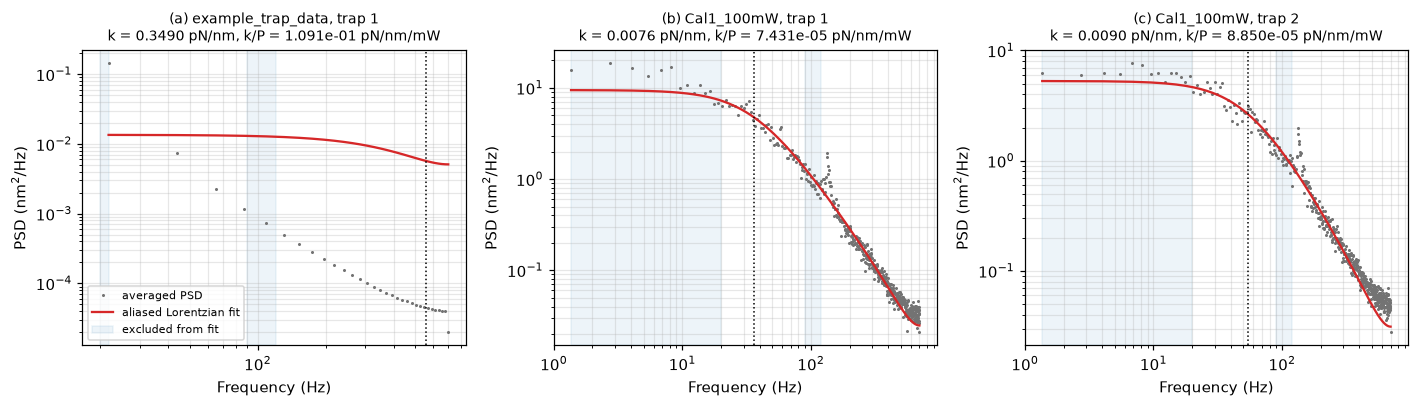

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("example_data/example_trap_data.dat", 0), ("example_data/Cal1_100mW.dat", 0), ("example_data/Cal1_100mW.dat", 1)]
for ax, (f, idx), letter in zip(axes, panels, "abc"):  # noqa: B007
    results, power = cal_results[f]
    r = results[idx]
    freq, psd, fit = r["frequency"], r["psd"], r["fit"]
    keep = freq > 0
    ax.loglog(freq[keep], psd[keep], ".", ms=2, color="0.45", label="averaged PSD", rasterized=True)
    ax.loglog(freq[keep], fit[keep], "-", color="tab:red", lw=1.5, label="aliased Lorentzian fit")
    ax.axvspan(freq[keep].min(), 20, color="tab:blue", alpha=0.08, label="excluded from fit")
    ax.axvspan(90, 120, color="tab:blue", alpha=0.08)
    ax.axvline(r["corner_frequency_hz"], color="k", ls=":", lw=1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (nm$^2$/Hz)")
    ax.set_title(f"({letter}) {Path(f).stem}, trap {r['track_index']}\n"
                 f"k = {r['stiffness_pn_per_nm']:.4f} pN/nm, k/P = {r['stiffness_per_mw']:.3e} pN/nm/mW", fontsize=9)
    ax.grid(True, which="both", alpha=0.3)
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
save_figure(fig, "fig01_psd_calibration")
plt.show()

**Figure 1.** Averaged power spectral densities (grey points) and fitted aliased Lorentzian models (red lines) for (a) the single-trace README example `example_trap_data.dat` and (b, c) traps 1 and 2 of the two-trap calibration file `Cal1_100mW.dat`. Shaded bands mark the default fit exclusions (below 20 Hz and 90–120 Hz), and the dotted line marks the fitted corner frequency. The stiffness in pN/nm and pN/nm/mW is printed above each panel. The fit in (a) is stuck at the γ upper bound and does not describe the short example spectrum; the fits in (b) and (c) follow the data. Files: [PNG](figures/fig01_psd_calibration.png), [SVG](figures/fig01_psd_calibration.svg).

## 2. The tidy data extractor: tether, oscillator, and puppet formats

Three modules turn raw run files into tidy, one-row-per-sample tables:

* `optical_trap_tidy.py` handles **tether-detection** runs (state codes 23–27, 29, and 30) and **oscillator** runs (states 3 and 4). It has a command-line interface and a Python API.
* `optical_trap_puppet.py` handles **puppet** runs through `read_puppet(...)`. It has no command-line interface.
* `optical_trap_toolbox.py` provides the shared loader, `load_normalized_trace`, and the state-run tools behind `optical_trap_state_report.py`.

The tidy command line has a required `--mode` flag with no default. The stiffness comes from `--k-per-mw` (in pN/nm/mW) or from a JSON calibration file passed with `--cal-file`. Optional flags add edge-tracking correction (`--edge-correction`) and tether identity and provenance (`--date`, `--bead`, `--tether-id`, `--link-previous`, `--target`, and `--registry`). Force is computed from trap 1 only, as $F = k_1 (x_1 - x_{1,\mathrm{ref}})$, where $k_1$ is `K_PER_MW` times the trap power from the `_Voltage.dat` file.

First, the next cell shows that leaving out `--mode` is an error.

In [5]:
run_cli(["optical_trap_tidy.py", "example_data/ParamData/tether1.dat"])

$ python optical_trap_tidy.py example_data/ParamData/tether1.dat


usage: optical_trap_tidy.py [-h] --mode {oscillator,tether-detection}
                            [--k-per-mw K_PER_MW] [--cal-file CAL_FILE]
                            [--output OUTPUT]
                            [--dv-dt-threshold DV_DT_THRESHOLD]
                            [--force-ref {measure_ref,high_hold_tail,fixed}]
                            [--force-ref-nm FORCE_REF_NM]
                            [--force-ref-frames FORCE_REF_FRAMES]
                            [--edge-correction] [--date DATE] [--bead BEAD]
                            [--tether-id TETHER_ID] [--link-previous]
                            [--target TARGET] [--registry REGISTRY]
                            files [files ...]
optical_trap_tidy.py: error: the following arguments are required: --mode
[exit code 2]


2

### 2.1 Calibration file for `--cal-file`

The README shows a calibration JSON with the key `k_per_mw`, but `load_calibration` in `optical_trap_tidy.py` reads only `k_trap1_pn_per_nm_per_mw`. A file written with the README key silently gives no stiffness, so forces come out as NaN. The next cell writes the calibration from Part 1 with the key the code reads, and shows what each key gives.

In [6]:
from optical_trap_tidy import load_calibration

cal_json = TMP / "calibration.json"
cal_json.write_text(json.dumps({
    "k_trap1_pn_per_nm_per_mw": K_PER_MW,
    "source_file": "Cal1_100mW",
    "fit_method": "aliased_psd",
}, indent=2))
readme_style_json = TMP / "calibration_readme_key.json"
readme_style_json.write_text(json.dumps({"k_per_mw": K_PER_MW}))

print("Key the code reads   ->", load_calibration(cal_json))
print("README example key   ->", load_calibration(readme_style_json))

Key the code reads   -> {'k_trap1': 7.430911101329399e-05, 'k_trap2': nan, 'calibration_id': 'Cal1_100mW__aliased_psd', 'k_trap1_pn_per_nm_per_mw': 7.430911101329399e-05, 'source_file': 'Cal1_100mW', 'fit_method': 'aliased_psd'}
README example key   -> {'k_trap1': nan, 'k_trap2': nan, 'calibration_id': 'calibration_readme_key', 'k_per_mw': 7.430911101329399e-05}


### 2.2 Tether-detection format (`--mode tether-detection`)

`example_data/ParamData/tether1.dat` is a tether-formation run (its `_params.dat` file says acquisition mode 1). The command below runs the whole pipeline with edge correction and tether-identity flags, writes a Parquet tidy table, and writes the attempts CSV, the session manifest, the provenance file, and a tether registry into the temporary folder. The date and bead number are placeholders; use your own experiment's values.

In [7]:
td_dir = TMP / "tether_detection"
run_cli([
    "optical_trap_tidy.py", "example_data/ParamData/tether1.dat",
    "--mode", "tether-detection",
    "--k-per-mw", f"{K_PER_MW:.6e}",
    "--edge-correction",
    "--date", "20260101", "--bead", "1",
    "--target", td_dir,
    "--registry", TMP / "tethers.csv",
    "--output", td_dir / "tether1_tidy.parquet",
])
print("\nFiles written:", sorted(p.name for p in td_dir.iterdir()))
print("\nRegistry:")
display(pd.read_csv(TMP / "tethers.csv")[["tether_id", "date", "bead", "tether_number", "source_file", "status"]])

$ python optical_trap_tidy.py example_data/ParamData/tether1.dat --mode tether-detection --k-per-mw 7.430911e-05 --edge-correction --date 20260101 --bead 1 --target /tmp/otc_user_guide_q9eb47z3/tether_detection --registry /tmp/otc_user_guide_q9eb47z3/tethers.csv --output /tmp/otc_user_guide_q9eb47z3/tether_detection/tether1_tidy.parquet


Attempts CSV written to /tmp/otc_user_guide_q9eb47z3/tether_detection/tether1_attempts.csv
Source                         FE_attempts Survived  Broke   Complete  Partial
-----------------------------------------------------------------------------------------
tether1                                  1        1      0          0        0

Tidy output written to /tmp/otc_user_guide_q9eb47z3/tether_detection/tether1_tidy.parquet

Session manifest written to /tmp/otc_user_guide_q9eb47z3/tether_detection/session_manifest.json
Provenance written to /tmp/otc_user_guide_q9eb47z3/tether_detection/provenance.json
Tether registry updated at /tmp/otc_user_guide_q9eb47z3/tethers.csv
tether1: unknown state code(s) encountered: state 28 (1546 frame(s)), state 35 (383 frame(s)), state 36 (140 frame(s))
[exit code 0]

Files written: ['provenance.json', 'session_manifest.json', 'tether1_attempts.csv', 'tether1_tidy.parquet']

Registry:


,tether_id,date,bead,tether_number,source_file,status
0,20260101_bp1_t1,20260101,1,1,example_data/ParamData/tether1.dat,active


The CLI printed a warning that it could not write the force-extension figure (`boolean value of NA is ambiguous`). This is a bug in the figure code of `optical_trap_tidy.py`, which compares each attempt number with the first row's attempt number, and that first row can be NA. The Python API below rebuilds the same table step by step, and we draw the force-extension curve ourselves in Figure 2.

In [8]:
import optical_trap_tidy as tidy


def tidy_pipeline(path, mode, k_per_mw, edge_correction=False, force_ref=None):
    # The same steps the tidy CLI runs, using the Python API.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # unknown-state and missing-calibration warnings are summarised below
        df = tidy.load_tidy(path, k_per_mw=k_per_mw, edge_correction=edge_correction)
        df = tidy.find_routine_segments(df, mode=mode)
        df = tidy.label_cycles(df)
        df = tidy.apply_valid_mask(df)
        method = force_ref or ("measure_ref" if mode == "tether_detection" else "high_hold_tail")
        df = tidy.compute_force_reference(df, method=method)
        df = tidy.flag_low_force_cycles(df)
        if method == "measure_ref":
            df = tidy.label_tether_detection_outcomes(df)
    return df


td = tidy_pipeline("example_data/ParamData/tether1.dat", "tether_detection", K_PER_MW, edge_correction=True)
td_summary = tidy.summarize_run(td)
print({k: td_summary[k] for k in ["source", "n_tether_attempts", "n_survived", "n_broke", "n_unknown_state_frames", "fraction_corrected"]})
display(tidy.extract_attempt_summary(td))

tether1: unknown state code(s) encountered: state 28 (1546 frame(s)), state 35 (383 frame(s)), state 36 (140 frame(s))


{'source': 'tether1', 'n_tether_attempts': 1, 'n_survived': 1, 'n_broke': 0, 'n_unknown_state_frames': 2069, 'fraction_corrected': 0.06441574415744157}


,fe_attempt,outcome,peak_force_pn,max_extension_nm,source,tether_id
0,1,survived,54.896977,7272.348825,tether1,<NA>


Figure 2 shows the pull-out and relax curves from the single attempt in this file. The run summary above also reports frames with state codes 28, 35, and 36, which are not in `STATE_LABELS` in `optical_trap_toolbox.py`, so they are counted as unknown.

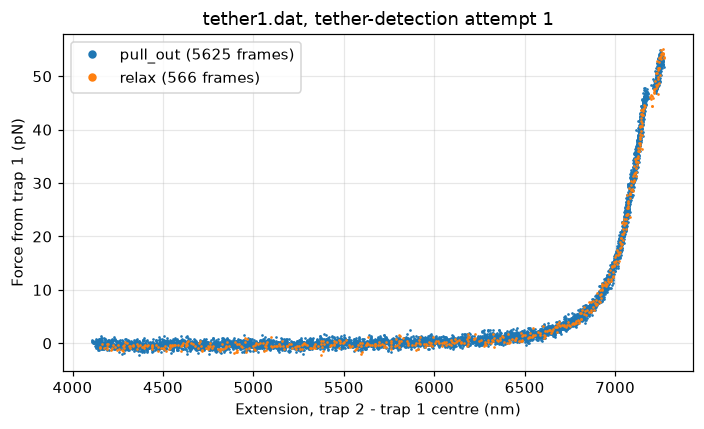

In [9]:
fe = tidy.extract_fe_curves(td)
fe = fe[fe["fe_attempt"].notna()]
fig, ax = plt.subplots(figsize=(6.5, 4))
for phase, color in [("pull_out", "tab:blue"), ("relax", "tab:orange")]:
    sub = fe[fe["phase"] == phase]
    ax.plot(sub["extension_nm"], sub["force_pn"], ".", ms=1.5, color=color, label=f"{phase} ({len(sub)} frames)", rasterized=True)
ax.set_xlabel("Extension, trap 2 - trap 1 centre (nm)")
ax.set_ylabel("Force from trap 1 (pN)")
ax.set_title("tether1.dat, tether-detection attempt 1")
ax.legend(markerscale=6)
ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig02_tether_detection_fe")
plt.show()

**Figure 2.** Force against extension for the one tether-detection attempt in `example_data/ParamData/tether1.dat`, built with the Python API, edge correction on, and `K_PER_MW` from Part 1. Pull-out frames are blue and relax frames are orange. The force reference is the mean trap-1 position of the preceding state-27 hold (`measure_ref`). Extension is the distance between the trap centres and still includes the bead radii. Files: [PNG](figures/fig02_tether_detection_fe.png), [SVG](figures/fig02_tether_detection_fe.svg).

### 2.3 Oscillator format (`--mode oscillator`)

`example_data/tether1_1.dat` is an oscillator run. We use `--cal-file` this time, give an explicit `--tether-id`, and turn on edge correction. The separate script `optical_trap_oscillator.py` gives per-cycle statistics and its own figure. Note that it has no `--mode` flag, even though the README says both CLIs require one; the last command below shows the error.

In [10]:
run_cli([
    "optical_trap_tidy.py", "example_data/tether1_1.dat",
    "--mode", "oscillator",
    "--cal-file", cal_json,
    "--edge-correction",
    "--tether-id", "20260101_bp1_t1",
    "--target", TMP / "oscillator",
    "--output", TMP / "oscillator" / "tether1_1_tidy.csv",
])
print()
run_cli(["optical_trap_oscillator.py", "example_data/tether1_1.dat", "--k-per-mw", f"{K_PER_MW:.6e}", "--edge-correction", "--output-dir", TMP / "oscillator_stats"])
print()
run_cli(["optical_trap_oscillator.py", "example_data/tether1_1.dat", "--mode", "oscillator", "--k-per-mw", f"{K_PER_MW:.6e}"])

$ python optical_trap_tidy.py example_data/tether1_1.dat --mode oscillator --cal-file /tmp/otc_user_guide_q9eb47z3/calibration.json --edge-correction --tether-id 20260101_bp1_t1 --target /tmp/otc_user_guide_q9eb47z3/oscillator --output /tmp/otc_user_guide_q9eb47z3/oscillator/tether1_1_tidy.csv


Source                         FE_attempts Survived  Broke   Complete  Partial
-----------------------------------------------------------------------------------------
tether1_1                                0        0      0          5        0

Tidy output written to /tmp/otc_user_guide_q9eb47z3/oscillator/tether1_1_tidy.csv

Session manifest written to /tmp/otc_user_guide_q9eb47z3/oscillator/session_manifest.json
Provenance written to /tmp/otc_user_guide_q9eb47z3/oscillator/provenance.json
[exit code 0]

$ python optical_trap_oscillator.py example_data/tether1_1.dat --k-per-mw 7.430911e-05 --edge-correction --output-dir /tmp/otc_user_guide_q9eb47z3/oscillator_stats


tether1_1: 5 complete cycle(s), 0 partial cycle(s). CSV → /tmp/otc_user_guide_q9eb47z3/oscillator_stats/tether1_1_oscillator.csv
tether1_1: figure → /tmp/otc_user_guide_q9eb47z3/oscillator_stats/tether1_1_oscillator.png
[exit code 0]

$ python optical_trap_oscillator.py example_data/tether1_1.dat --mode oscillator --k-per-mw 7.430911e-05


usage: optical_trap_oscillator.py [-h] [--k-per-mw K_PER_MW]
                                  [--cal-file CAL_FILE]
                                  [--output-dir OUTPUT_DIR]
                                  [--dv-dt-threshold DV_DT_THRESHOLD]
                                  [--force-ref {high_hold_tail,fixed}]
                                  [--force-ref-frames FORCE_REF_FRAMES]
                                  [--force-ref-nm FORCE_REF_NM]
                                  [--edge-correction]
                                  files [files ...]
optical_trap_oscillator.py: error: unrecognized arguments: --mode oscillator
[exit code 2]


2

In [11]:
osc_raw = tidy_pipeline("example_data/tether1_1.dat", "oscillator", K_PER_MW, edge_correction=False)
osc_ec = tidy_pipeline("example_data/tether1_1.dat", "oscillator", K_PER_MW, edge_correction=True)
s = tidy.summarize_run(osc_ec)
print({k: s[k] for k in ["source", "n_complete_oscillator_cycles", "n_partial_oscillator_cycles", "n_force_suspect_cycles", "total_corrected", "fraction_corrected"]})
for name, d in [("no edge correction", osc_raw), ("edge correction", osc_ec)]:
    o = d[(d["mode"] == "oscillator") & d["valid"]]
    print(f"{name:>20}: oscillator force 0.1st-99.9th percentile = "
          f"{np.nanpercentile(o['force_pn'], 0.1):8.2f} to {np.nanpercentile(o['force_pn'], 99.9):6.2f} pN")

{'source': 'tether1_1', 'n_complete_oscillator_cycles': 5, 'n_partial_oscillator_cycles': 0, 'n_force_suspect_cycles': 0, 'total_corrected': 10470, 'fraction_corrected': 0.043638818959337126}
  no edge correction: oscillator force 0.1st-99.9th percentile =  -312.88 to  32.64 pN
     edge correction: oscillator force 0.1st-99.9th percentile =    -2.23 to  32.64 pN


Figure 3 shows why `--edge-correction` matters for this file. Without it, edge-tracking errors in trap 1 produce force spikes of hundreds of piconewtons; with it, the five oscillator cycles are clean. The printed percentiles above give the numbers.

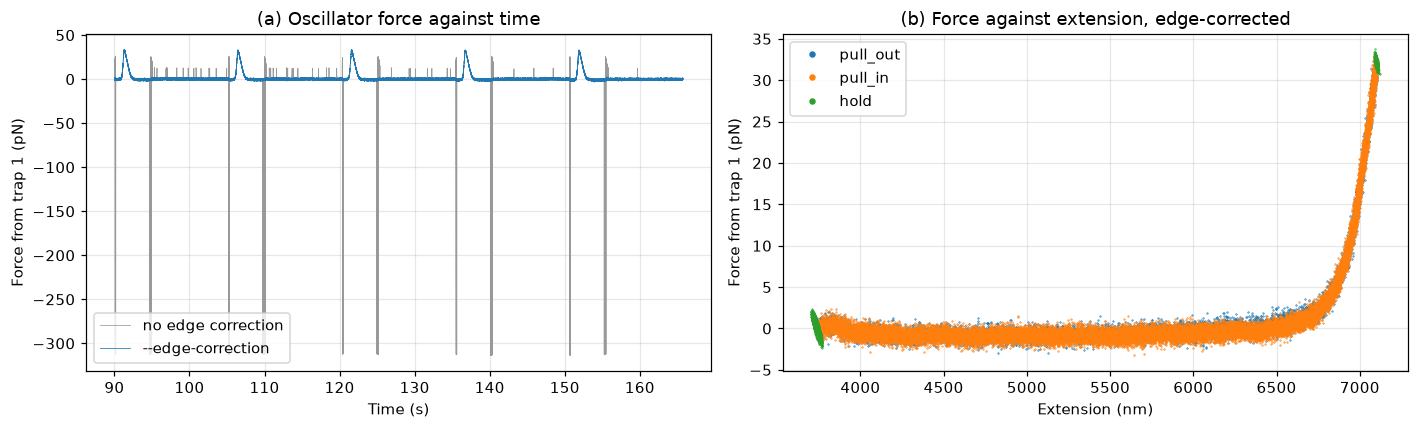

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
o_raw = osc_raw[osc_raw["mode"] == "oscillator"]
o_ec = osc_ec[(osc_ec["mode"] == "oscillator") & osc_ec["valid"]]
axes[0].plot(o_raw["time_s"], o_raw["force_pn"], color="0.6", lw=0.5, label="no edge correction", rasterized=True)
axes[0].plot(o_ec["time_s"], o_ec["force_pn"], color="tab:blue", lw=0.5, label="--edge-correction", rasterized=True)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Force from trap 1 (pN)")
axes[0].set_title("(a) Oscillator force against time")
axes[0].legend(loc="lower left")
for phase, color in [("pull_out", "tab:blue"), ("pull_in", "tab:orange"), ("hold", "tab:green")]:
    sub = o_ec[o_ec["phase"] == phase]
    axes[1].plot(sub["extension_nm"], sub["force_pn"], ".", ms=0.8, color=color, label=phase, rasterized=True)
axes[1].set_xlabel("Extension (nm)")
axes[1].set_ylabel("Force from trap 1 (pN)")
axes[1].set_title("(b) Force against extension, edge-corrected")
axes[1].legend(markerscale=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig03_oscillator_edge_correction")
plt.show()

**Figure 3.** Oscillator run `example_data/tether1_1.dat` processed with the tidy Python API and `K_PER_MW` from Part 1. (a) Trap-1 force against time without edge correction (grey) and with edge correction (blue); the uncorrected trace has large negative spikes from mis-tracked edges. (b) Edge-corrected force against extension, coloured by phase. The force reference for each cycle is the tail of its high-voltage hold (`high_hold_tail`). Files: [PNG](figures/fig03_oscillator_edge_correction.png), [SVG](figures/fig03_oscillator_edge_correction.svg).

### 2.4 Puppet format (`read_puppet`)

Puppet runs have no CLI mode, so they are read in Python with `read_puppet(path, stiffness=K_PER_MW)`. The power comes from the `_Voltage.dat` file, and holds and ramps are found from the smoothed voltage. By default, each segment's force reference is the mean trap-1 position of the preceding hold. That works for pull-out ramps, which start from the relaxed high-voltage hold, but pull-in ramps start from the stretched low-voltage hold, so their force is measured from a stretched reference and comes out negative. The optional `force_ref_nm` argument fixes one reference for the whole run. Here we set it to the mean trap-1 position over the relaxed high-voltage holds, which matches the trap-1-only force definition for both ramp directions.

In [13]:
from optical_trap_puppet import read_puppet

pup_default = read_puppet("example_data/tether1_puppet.dat", stiffness=K_PER_MW, detect_rupture=True)
hold = pup_default[(pup_default["phase"] == "hold") & pup_default["valid"]]
high_v = hold["hold_voltage"].max()
relaxed = hold[hold["hold_voltage"] >= high_v - 0.05]
FORCE_REF_NM = float(relaxed["trap1_nm"].mean())
pup = read_puppet("example_data/tether1_puppet.dat", stiffness=K_PER_MW, force_ref_nm=FORCE_REF_NM)

from optical_trap_analysis import infer_analysis_cycle
n_pup_cycles = pd.Series(infer_analysis_cycle(pup)).dropna().nunique()
print(f"Frames: {len(pup)}, segments: {pup['segment_id'].nunique()}, pull-out/pull-in cycles: {n_pup_cycles}")
print(f"Power from _Voltage.dat: {pup['power_mw'].iloc[0]:.1f} mW; hold voltages: {[float(v) for v in sorted(pup['hold_voltage'].dropna().round(2).unique())]} V")
print(f"Fixed force reference (mean trap 1 over {high_v:.2f} V holds): {FORCE_REF_NM:.1f} nm")
print(f"Bead diameters from edge spacing: {pup['bead1_diameter_nm'].iloc[0]:.0f} nm and {pup['bead2_diameter_nm'].iloc[0]:.0f} nm (used for extension_nm_corrected)")
for name, d in [("default (preceding hold)", pup_default), ("fixed force_ref_nm", pup)]:
    med = d.groupby("phase")["force_pn"].median()
    print(f"{name:>26}: median force pull_out = {med['pull_out']:6.2f} pN, pull_in = {med['pull_in']:6.2f} pN")
print("Ruptures flagged by detect_rupture=True:", int(pup_default["ruptured"].sum()))

Frames: 89059, segments: 37, pull-out/pull-in cycles: 9
Power from _Voltage.dat: 1007.0 mW; hold voltages: [5.5, 8.75] V
Fixed force reference (mean trap 1 over 8.75 V holds): 6862.9 nm
Bead diameters from edge spacing: 3639 nm and 2771 nm (used for extension_nm_corrected)
  default (preceding hold): median force pull_out =  12.96 pN, pull_in = -26.08 pN
        fixed force_ref_nm: median force pull_out =  12.98 pN, pull_in =  13.15 pN
Ruptures flagged by detect_rupture=True: 0


Figure 4 compares the two force references over the whole puppet run. With the default reference, every pull-in ramp has a negative force; with the fixed reference, pull-out and pull-in overlap as expected.

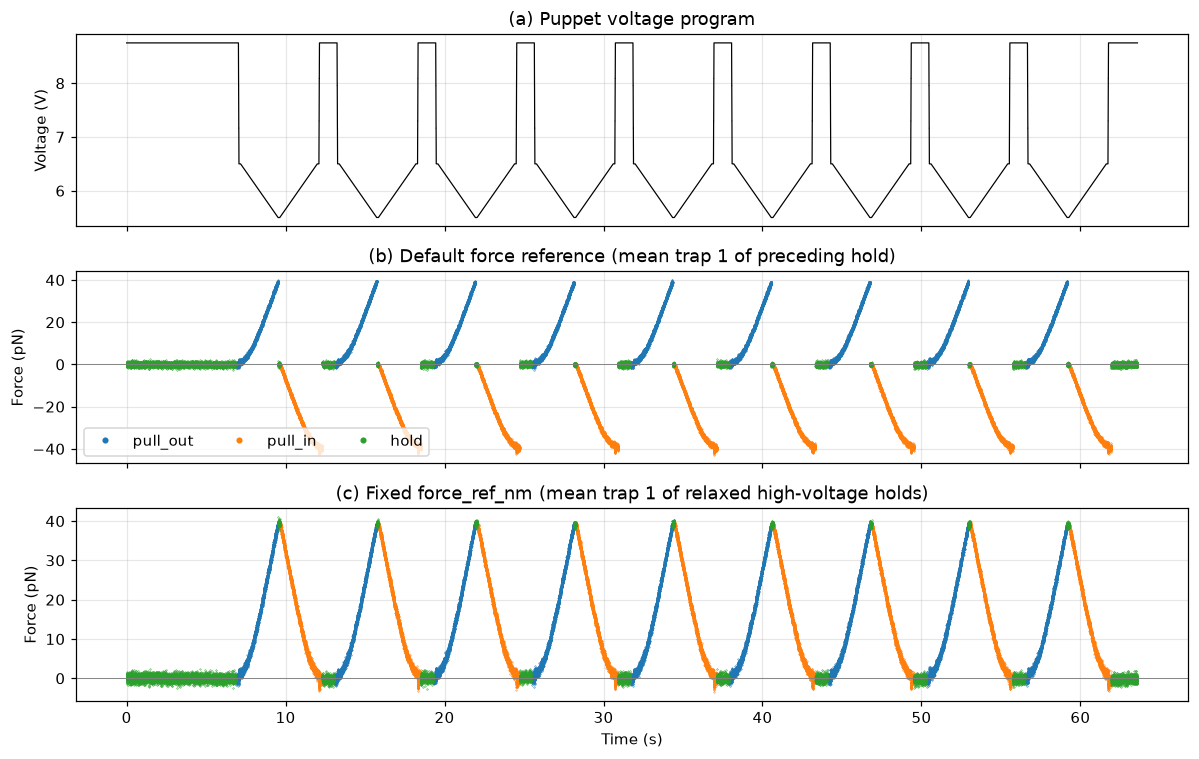

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(pup["time_s"], pup["voltage_v"], color="k", lw=0.8)
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("(a) Puppet voltage program")
colors = {"pull_out": "tab:blue", "pull_in": "tab:orange", "hold": "tab:green"}
for ax, d, title in [(axes[1], pup_default, "(b) Default force reference (mean trap 1 of preceding hold)"),
                     (axes[2], pup, "(c) Fixed force_ref_nm (mean trap 1 of relaxed high-voltage holds)")]:
    for phase, color in colors.items():
        sub = d[(d["phase"] == phase) & d["valid"]]
        ax.plot(sub["time_s"], sub["force_pn"], ".", ms=0.6, color=color, label=phase, rasterized=True)
    ax.set_ylabel("Force (pN)")
    ax.set_title(title)
    ax.axhline(0, color="0.5", lw=0.6)
axes[1].legend(markerscale=10, ncol=3, loc="lower left")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig04_puppet_force_reference")
plt.show()

**Figure 4.** Puppet run `example_data/tether1_puppet.dat` read with `read_puppet` and `K_PER_MW` from Part 1. (a) The programmed voltage, alternating between a relaxed high-voltage hold and a stretched low-voltage hold. (b) Force with the default preceding-hold reference: pull-in ramps start from the stretched hold and therefore read negative. (c) Force with a fixed `force_ref_nm` taken from the relaxed holds, which gives a consistent trap-1 force for both ramp directions. Only frames with `valid = True` are plotted (one frame carries the lost-edge sentinel). Files: [PNG](figures/fig04_puppet_force_reference.png), [SVG](figures/fig04_puppet_force_reference.svg).

### 2.5 State reports

`optical_trap_state_report.py` lists the contiguous state-code runs in any trace, which is a quick way to see what a file contains before choosing a mode. The README's example uses `Matlab_Files/tether1_part2.dat`, and saved outputs are in `sample_reports/`. The next cell regenerates the report into the temporary folder and compares it with the saved CSV. The saved sample report lists a single run of state 0, while the current loader finds oscillator states 3 and 4, so the files in `sample_reports/` are out of date. Figure 5 shows the regenerated state-against-time plot.

$ python optical_trap_state_report.py --file Matlab_Files/tether1_part2.dat --csv /tmp/otc_user_guide_q9eb47z3/state_report.csv --json /tmp/otc_user_guide_q9eb47z3/state_report.json --plot /tmp/otc_user_guide_q9eb47z3/state_report.png


State report
Force-extension pulls (state 29): 0
state_code label                        conf     runs  samples    dur(s)    frac
         3 oscillator_hold              high        4    14286    10.198   0.265
         4 oscillator_ramp              high        4    24157    17.246   0.448
         5 background_5                 high        1        3     0.001   0.000
         7 background_7                 high        1     6655     4.751   0.123
        19 background_19                high        1        2     0.001   0.000
        20 background_20                high        1     8843     6.313   0.164

Run boundaries:
  state 7: idx 0-6654; time 0.000s to 4.751s
  state 5: idx 6655-6657; time 4.752s to 4.753s
  state 4: idx 6658-12696; time 4.754s to 9.065s
  state 3: idx 12697-12836; time 9.066s to 9.165s
  state 4: idx 12837-18875; time 9.166s to 13.477s
  state 3: idx 18876-25878; time 13.478s to 18.478s
  state 4: idx 25879-31918; time 18.478s to 22.790s
  state 3: idx 31919

,state_code,label,confidence,run_count,total_samples,total_duration_s,fraction_of_trace
0,0,unknown_state_0,low,1,53946,38.51819,1.0


Regenerated report:


,state_code,label,confidence,run_count,total_samples,total_duration_s,fraction_of_trace
0,3,oscillator_hold,high,4,14286,10.19772,0.264751
1,4,oscillator_ramp,high,4,24157,17.24589,0.447734
2,5,background_5,high,1,3,0.00143,0.000037
3,7,background_7,high,1,6655,4.75114,0.123348
4,19,background_19,high,1,2,0.00071,0.000018
5,20,background_20,high,1,8843,6.31342,0.163907


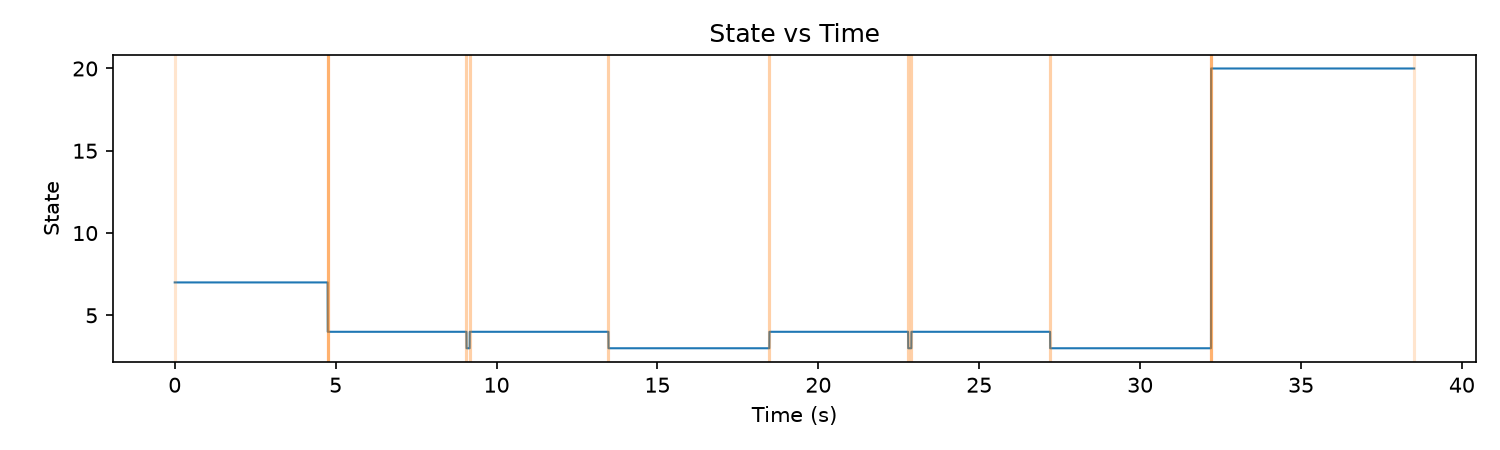

In [15]:
run_cli(["optical_trap_state_report.py", "--file", "Matlab_Files/tether1_part2.dat",
         "--csv", TMP / "state_report.csv", "--json", TMP / "state_report.json", "--plot", TMP / "state_report.png"])
print("\nSaved sample report (sample_reports/tether1_part2_state_report.csv):")
display(pd.read_csv("sample_reports/tether1_part2_state_report.csv"))
print("Regenerated report:")
display(pd.read_csv(TMP / "state_report.csv"))
shutil.copy(TMP / "state_report.png", FIG_DIR / "fig05_state_report_tether1_part2.png")
display(Image(filename=str(TMP / "state_report.png"), width=650))

**Figure 5.** State code against time for `Matlab_Files/tether1_part2.dat`, written by `optical_trap_state_report.py --plot` (150 dpi PNG from the script; no SVG is available). The run shows four oscillator ramps (state 4) separated by holds (state 3), framed by background states 7 and 20. File: [PNG](figures/fig05_state_report_tether1_part2.png).

## 3. From a delta extension to a distance comparison

The DNA caliper is a long dsDNA construct (13,250 bp in Andrew's design) with a loop region that closes when the target binds. Closing the loop shortens the tether, so at the same force a looped tether is shorter than an open one. The **delta extension** is that difference in length at a given force.

Andrew's conventions, which this section follows, are:

* Delta extension against force basically plateaus above about 5 pN, and on that plateau it is treated as proportional to the distance $d$.
* The model's zero-target delta, $\Delta_{0T} = x_{\mathrm{full}} - x_{0T}$, is the delta expected if the loop closed with zero target length.
* The residual $\Delta_{\mathrm{theory}} - \Delta_{\mathrm{experiment}}$ is a **model–data difference**. It is not a reliable estimate of $d$.
* Fits fix the contour length from the known DNA length and $L_p$ at 50 nm for dsDNA, with only the offset free.

### 3.1 Which example data contain a loop-closure signal?

`optical_trap_analysis.summarize_dynamic_delta_extension` computes pull_out − pull_in extension in adaptive force bins for each cycle. Note the sign: the Python function returns pull_out − pull_in, whereas the MATLAB `dynamic_delta.m` in `Matlab_Files/CD43_Oscilator/` uses ramp-down minus ramp-up, which is pull_in − pull_out. We report the MATLAB sign, $\Delta_{\mathrm{exp}}$ = pull_in − pull_out, so that a closed loop on pull-out gives a positive delta.

The next cell runs the function on the two example runs from Part 2 and on `Matlab_Files/tether1_part2.dat`.

In [16]:
from optical_trap_analysis import summarize_dynamic_delta_extension, detect_dynamic_rupture_events


def plateau_delta(per_cycle_summary, fmin=5.0, fmax=30.0):
    # Mean MATLAB-sign delta (pull_in - pull_out) over force bins between fmin and fmax.
    s = per_cycle_summary[(per_cycle_summary["mean_force_pn"] >= fmin) & (per_cycle_summary["mean_force_pn"] <= fmax)]
    return float(-s["delta_extension_mean_nm"].mean()), len(s)


osc_rows = osc_ec[(osc_ec["mode"] == "oscillator") & osc_ec["cycle_complete"].astype("boolean").fillna(False)]
_, osc_delta = summarize_dynamic_delta_extension(osc_rows, force_bin_target_count=400)
_, pup_delta = summarize_dynamic_delta_extension(pup, force_bin_target_count=400)

p2 = tidy_pipeline("Matlab_Files/tether1_part2.dat", "oscillator", K_PER_MW, edge_correction=True)
p2_osc = p2[(p2["mode"] == "oscillator") & p2["cycle_complete"].astype("boolean").fillna(False)]
cycle_fmax = p2_osc.groupby("cycle")["force_pn"].max()
print("tether1_part2 peak force per complete cycle (pN):", cycle_fmax.round(1).to_dict())
loaded_cycles = cycle_fmax[cycle_fmax > 10].index.tolist()
p2_use = p2_osc[p2_osc["cycle"].isin(loaded_cycles)]
p2_cycles, p2_delta = summarize_dynamic_delta_extension(p2_use, force_bin_target_count=150)
p2_events = detect_dynamic_rupture_events(p2_use)

for name, summ in [("example_data/tether1_1.dat (oscillator)", osc_delta),
                   ("example_data/tether1_puppet.dat (puppet, fixed ref)", pup_delta),
                   ("Matlab_Files/tether1_part2.dat (oscillator, loaded cycles)", p2_delta)]:
    d, n = plateau_delta(summ)
    print(f"{name:<58} mean Delta_exp over 5-30 pN = {d:7.1f} nm ({n} bins)")
print("\nRupture events in tether1_part2 loaded cycles:")
display(p2_events[["analysis_cycle", "rupture_force_pn", "loading_rate_pn_per_s", "pre_rupture_extension_nm"]])

tether1_part2 peak force per complete cycle (pN): {np.int64(1): 57.6, np.int64(2): 2.6}
example_data/tether1_1.dat (oscillator)                    mean Delta_exp over 5-30 pN =    -0.8 nm (4 bins)
example_data/tether1_puppet.dat (puppet, fixed ref)        mean Delta_exp over 5-30 pN =    -0.1 nm (44 bins)
Matlab_Files/tether1_part2.dat (oscillator, loaded cycles) mean Delta_exp over 5-30 pN =   187.1 nm (6 bins)

Rupture events in tether1_part2 loaded cycles:


,analysis_cycle,rupture_force_pn,loading_rate_pn_per_s,pre_rupture_extension_nm
0,1,42.034855,8.011513,7058.311105


The two `example_data` runs give a plateau delta within a few nanometres of zero, so they contain no loop-closure signal. The oscillator file `Matlab_Files/tether1_part2.dat` is different. Its first complete cycle reaches high force and shows a delta of well over 100 nm that holds between about 5 and 30 pN and collapses at a rupture near 42 pN, which is consistent with a loop that is closed on pull-out and opens at the rupture. Its second cycle never loads above a few piconewtons, so we leave it out. The exact numbers are printed above.

The repository does not record the construct or loop length for this tether. In the comparison below, we therefore use the 200 nm (588 bp) caliper loop from the worked example in `MODEL_GUIDE.md` and the 13,250 bp full-length construct. These are illustrative parameter choices, not measured properties of this tether.

In [17]:
import optical_trap_dna as dna

RISE_DS = 0.34      # nm/bp
RISE_SS = 0.63      # nm/nt
FULL_BP = 13_250    # full-length construct (Andrew's design)
LOOP_BP = 588       # illustrative: the 200 nm caliper loop from MODEL_GUIDE.md
DS_BP = FULL_BP - LOOP_BP

# Every key is set explicitly; see Part 4 for why that matters.
DS_PARAMS = {"rise_per_unit_nm": RISE_DS, "persistence_length_nm": 50.0, "stretch_modulus_pn": 1200.0, "model": "extensible_wlc"}
LOOP_PARAMS = dict(DS_PARAMS)
LOOP_PARAMS_SHORT_LP = dict(DS_PARAMS, persistence_length_nm=29.1)  # finite-size Lp for a 200 nm loop (MODEL_GUIDE.md, Figure 3)

meas = p2_delta.dropna(subset=["mean_force_pn"]).copy()
meas["delta_exp_nm"] = -meas["delta_extension_mean_nm"]          # MATLAB sign: pull_in - pull_out
plateau = meas[(meas["mean_force_pn"] >= 5) & (meas["mean_force_pn"] <= 30)]
F_plateau = plateau["mean_force_pn"].to_numpy()

model_0T = dna.delta_extension_zero_target(F_plateau, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS)
model_0T_short = dna.delta_extension_zero_target(F_plateau, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS_SHORT_LP)
cmp = dna.compare_delta_extension(plateau["delta_exp_nm"].to_numpy(), F_plateau, model_0T)

print(f"Plateau bins used: {len(plateau)} (5-30 pN)")
print(f"Measured Delta_exp, mean over plateau: {plateau['delta_exp_nm'].mean():.1f} nm")
print(f"Model Delta_0T (Lp 50 nm loop), mean over same forces: {model_0T.mean():.1f} nm")
print(f"Model Delta_0T (Lp 29.1 nm loop), mean over same forces: {model_0T_short.mean():.1f} nm")
print(f"compare_delta_extension: RMSE = {cmp['rmse_nm']:.1f} nm, median |residual| = {cmp['mad_nm']:.1f} nm")
print(f"Model-data difference Delta_0T - Delta_exp, mean = {np.mean(-cmp['residual_nm']):.1f} nm (not a distance estimate)")

Plateau bins used: 6 (5-30 pN)
Measured Delta_exp, mean over plateau: 187.1 nm
Model Delta_0T (Lp 50 nm loop), mean over same forces: 195.2 nm
Model Delta_0T (Lp 29.1 nm loop), mean over same forces: 192.8 nm
compare_delta_extension: RMSE = 8.8 nm, median |residual| = 6.7 nm
Model-data difference Delta_0T - Delta_exp, mean = 8.1 nm (not a distance estimate)


Figure 6 puts the measurement and the model side by side. Panel (a) shows the raw pull-out and pull-in curves of the loaded cycle, panel (b) shows the measured delta with the illustrative $\Delta_{0T}$ curves, and panel (c) shows the model–data difference. `compare_delta_extension` returns measured − model as `residual_nm`; the MATLAB code plots model − measured, so panel (c) uses that sign.

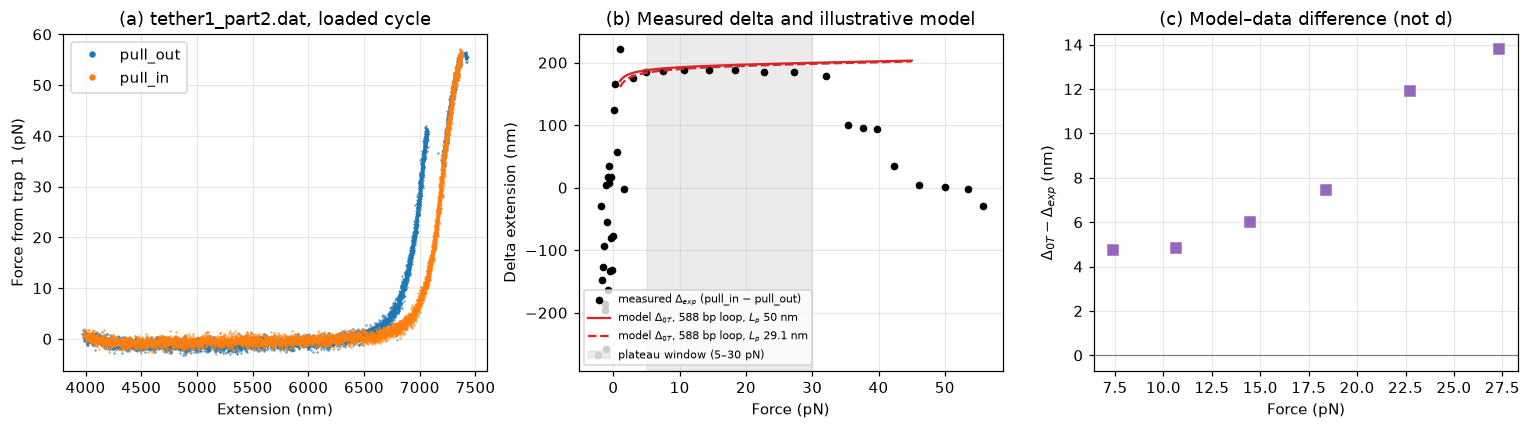

In [18]:
F_grid = np.linspace(1, 45, 120)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
c1 = p2_use[p2_use["valid"]]
for phase, color in [("pull_out", "tab:blue"), ("pull_in", "tab:orange")]:
    sub = c1[c1["phase"] == phase]
    axes[0].plot(sub["extension_nm"], sub["force_pn"], ".", ms=0.8, color=color, label=phase, rasterized=True)
axes[0].set_xlabel("Extension (nm)")
axes[0].set_ylabel("Force from trap 1 (pN)")
axes[0].set_title("(a) tether1_part2.dat, loaded cycle")
axes[0].legend(markerscale=8)

axes[1].plot(meas["mean_force_pn"], meas["delta_exp_nm"], "o", ms=4, color="k", label=r"measured $\Delta_{exp}$ (pull_in − pull_out)")
axes[1].plot(F_grid, dna.delta_extension_zero_target(F_grid, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS), "-", color="tab:red",
             label=r"model $\Delta_{0T}$, 588 bp loop, $L_p$ 50 nm")
axes[1].plot(F_grid, dna.delta_extension_zero_target(F_grid, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS_SHORT_LP), "--", color="tab:red",
             label=r"model $\Delta_{0T}$, 588 bp loop, $L_p$ 29.1 nm")
axes[1].axvspan(5, 30, color="0.85", alpha=0.5, label="plateau window (5–30 pN)")
axes[1].set_xlabel("Force (pN)")
axes[1].set_ylabel("Delta extension (nm)")
axes[1].set_title("(b) Measured delta and illustrative model")
axes[1].legend(fontsize=7, loc="lower left")

axes[2].plot(F_plateau, -cmp["residual_nm"], "s", color="tab:purple")
axes[2].axhline(0, color="0.5", lw=0.8)
axes[2].set_xlabel("Force (pN)")
axes[2].set_ylabel(r"$\Delta_{0T} - \Delta_{exp}$ (nm)")
axes[2].set_title("(c) Model–data difference (not d)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig06_measured_delta_vs_model")
plt.show()

**Figure 6.** Measured delta extension from `Matlab_Files/tether1_part2.dat` compared with the toolkit's zero-target model. (a) Pull-out (blue) and pull-in (orange) force-extension data for the loaded oscillator cycle, edge-corrected, with trap-1 force from `K_PER_MW`. (b) Measured $\Delta_{\mathrm{exp}}$ = pull_in − pull_out in adaptive force bins (black), and $\Delta_{0T}$ for an illustrative 588 bp (200 nm) dsDNA loop in a 13,250 bp construct, with loop $L_p$ = 50 nm (solid) or the finite-size value of 29.1 nm (dashed). The loop length is not recorded for this tether, so the model curves are illustrative only. Bins below about 2 pN scatter widely because the extension difference there is dominated by noise, and the delta falls to about zero above the rupture near 42 pN. (c) The model–data difference $\Delta_{0T} - \Delta_{\mathrm{exp}}$ over the 5–30 pN plateau; per Andrew's convention this is not a reliable estimate of $d$. Files: [PNG](figures/fig06_measured_delta_vs_model.png), [SVG](figures/fig06_measured_delta_vs_model.svg).

### 3.2 The toolkit's distance estimate (model only)

`distance_estimate` returns $\Delta_{0T} - \Delta_{\mathrm{target}} = x_{\mathrm{target}} - x_{0T}$, the extension that the target block adds when it bridges the loop. No dataset in the repository contains a matched full-length, zero-target, and target set for one tether, so this subsection is a **synthetic, model-only illustration**. We use the same illustrative 13,250 bp construct with a 588 bp loop, and a 40 nt ssDNA target block ($L_p$ = 1.25 nm, 0.63 nm/nt, $S$ = 800 pN, `wlc`). Figure 7 shows the three model curves.

F =   5.0 pN: Delta_0T =  187.9 nm, Delta_target =  174.1 nm, distance estimate =  13.8 nm
F =  10.0 pN: Delta_0T =  192.5 nm, Delta_target =  175.1 nm, distance estimate =  17.4 nm
F =  20.0 pN: Delta_0T =  196.8 nm, Delta_target =  177.0 nm, distance estimate =  19.8 nm
F =  40.0 pN: Delta_0T =  202.0 nm, Delta_target =  180.6 nm, distance estimate =  21.5 nm
ssDNA target contour length = 25.2 nm


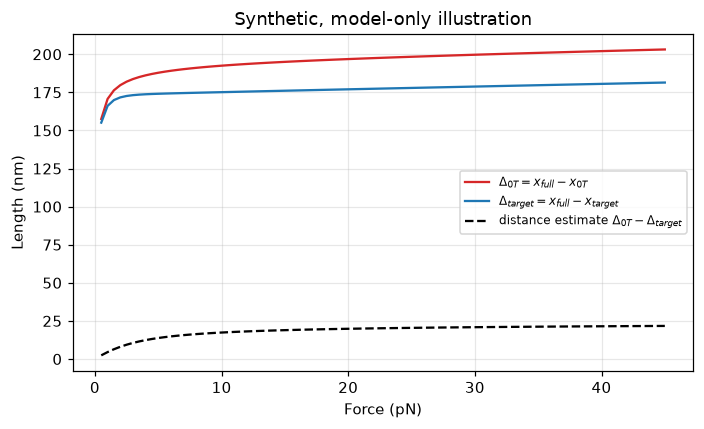

In [19]:
TARGET_NT = 40  # illustrative short ssDNA target block (for example two 20 nt arms)
SS_PARAMS = {"rise_per_unit_nm": RISE_SS, "persistence_length_nm": 1.25, "stretch_modulus_pn": 800.0, "model": "wlc"}

F_model = np.linspace(0.5, 45, 90)
d0T = dna.delta_extension_zero_target(F_model, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS)
dT = dna.delta_extension_target(F_model, DS_BP, TARGET_NT, LOOP_BP, DS_PARAMS, SS_PARAMS, LOOP_PARAMS)
dist = dna.distance_estimate(F_model, DS_BP, TARGET_NT, LOOP_BP, DS_PARAMS, SS_PARAMS, LOOP_PARAMS)
for f in (5, 10, 20, 40):
    i = int(np.argmin(np.abs(F_model - f)))
    print(f"F = {F_model[i]:5.1f} pN: Delta_0T = {d0T[i]:6.1f} nm, Delta_target = {dT[i]:6.1f} nm, distance estimate = {dist[i]:5.1f} nm")
print(f"ssDNA target contour length = {TARGET_NT * RISE_SS:.1f} nm")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(F_model, d0T, color="tab:red", label=r"$\Delta_{0T} = x_{full} - x_{0T}$")
ax.plot(F_model, dT, color="tab:blue", label=r"$\Delta_{target} = x_{full} - x_{target}$")
ax.plot(F_model, dist, color="k", ls="--", label=r"distance estimate $\Delta_{0T} - \Delta_{target}$")
ax.set_xlabel("Force (pN)")
ax.set_ylabel("Length (nm)")
ax.set_title("Synthetic, model-only illustration")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig07_model_distance_estimate")
plt.show()

**Figure 7.** Synthetic, model-only illustration of the toolkit's delta-extension and distance functions for an illustrative 13,250 bp construct (12,662 bp dsDNA arm plus a 588 bp loop, both `extensible_wlc`, $L_p$ 50 nm, $S$ 1200 pN) with a 40 nt ssDNA target block (`wlc`, $L_p$ 1.25 nm, 0.63 nm/nt, $S$ 800 pN). No measured data are shown. The distance estimate rises toward the target's 25.2 nm contour length as force increases. Files: [PNG](figures/fig07_model_distance_estimate.png), [SVG](figures/fig07_model_distance_estimate.svg).

## 4. The DNA force-extension toolkit (`optical_trap_dna.py`)

The toolkit has one generic single-segment function, `single_polymer_extension(force, contour_length, Lp, S, model=..., rise_per_unit_nm=...)`, and its inverse `single_polymer_force`. Pass the contour length in nm with the default `rise_per_unit_nm=1.0`, or pass a number of bases with `rise_per_unit_nm` set to the rise per base. The models are `wlc`, `extensible_wlc` (additive stretch term), `fjc`, and `extensible_fjc` (multiplicative Smith form). The construct functions, `full_length_curve`, `zero_target_curve`, and `target_curve`, take a parameter dictionary for each segment. `MODEL_GUIDE.md` in `docs/dna_fe_toolkit/` explains the physics.

The parameters used in this notebook follow the model guide:

| Segment | Rise | $L_p$ | $S$ | Model |
|---|---|---|---|---|
| dsDNA | 0.34 nm/bp | 50 nm | 1200 pN | `wlc` at low force, `extensible_wlc` up to about 60 pN |
| ssDNA (caliper arms, about 150 mM salt) | 0.63 nm/nt | 1.0–1.5 nm (1.25 nm central) | 800 pN | `wlc` |

### 4.1 Pitfalls you must handle explicitly

The cells below check each known pitfall against the code in this checkout. In short:

1. The construct functions read each parameter dictionary with **dsDNA fallbacks** (`persistence_length_nm` 50.0, `stretch_modulus_pn` 1200.0, `model` `"wlc"`, `rise_per_unit_nm` 1.0) and never use `_DEFAULT_SSDNA`. An ssDNA dictionary must therefore set every key.
2. The dictionary key is `rise_per_unit_nm`, while the defaults dictionaries use `rise_per_base_nm`. A dictionary that uses `rise_per_base_nm` is silently treated as having a rise of 1.0 nm.
3. `_DEFAULT_SSDNA` lists a 0.63 nm rise and the `fjc` model, but neither is ever read. Its 0.75 nm $L_p$ and 800 pN $S$ are used only by `single_polymer_extension` and `single_polymer_force` with `dna_type="ssdna"`.
4. The FJC Kuhn length is fixed at $b = 2L_p$, so there is no separate Kuhn-length input.
5. A positive stretch modulus is required even for the inextensible `wlc` and `fjc` models, which ignore it.
6. If the parallel force split in `target_curve` finds no root, it silently falls back to an equal split. At total forces below about 1e-12 pN the same fallback path raises a `ValueError` instead.
7. A scalar force returns a one-element array rather than a float for the `wlc` and `extensible_wlc` models, so convert explicitly when you need a number.

In [20]:
import inspect
F10 = 10.0


def scalar(x):
    # The toolkit returns a 1-element array for a scalar force with some models, so convert explicitly.
    return float(np.ravel(x)[0])


print("Shape returned for a scalar force, wlc:", np.shape(dna.single_polymer_extension(F10, 100.0, 50.0, 1200.0, model="wlc")),
      "| extensible_wlc:", np.shape(dna.single_polymer_extension(F10, 100.0, 50.0, 1200.0, model="extensible_wlc")),
      "| fjc:", np.shape(dna.single_polymer_extension(F10, 100.0, 0.75, 800.0, model="fjc")))

print("_DEFAULT_DSDNA =", dna._DEFAULT_DSDNA)
print("_DEFAULT_SSDNA =", dna._DEFAULT_SSDNA)

# 1. A partial ssDNA dict silently picks up dsDNA values.
partial_ss = {"rise_per_unit_nm": RISE_SS, "model": "wlc"}  # Lp and S left out
x_partial = dna.zero_target_curve(F10, TARGET_NT, partial_ss)
x_full_ss = dna.zero_target_curve(F10, TARGET_NT, SS_PARAMS)
print(f"\n1. 40 nt ssDNA at 10 pN: complete dict -> {scalar(x_full_ss):.2f} nm; dict without Lp/S -> {scalar(x_partial):.2f} nm (Lp 50 nm used)")

# 2. rise_per_base_nm is ignored by the construct functions.
wrong_key = {"rise_per_base_nm": RISE_SS, "persistence_length_nm": 1.25, "stretch_modulus_pn": 800.0, "model": "wlc"}
x_wrong = dna.zero_target_curve(F10, TARGET_NT, wrong_key)
print(f"2. Same dict with rise_per_base_nm instead of rise_per_unit_nm -> {scalar(x_wrong):.2f} nm (40 nt treated as 40 nm)")

# 3. dna_type='ssdna' fills Lp=0.75 and S=800 but keeps model='wlc' and rise=1.0.
x_dnatype = dna.single_polymer_extension(F10, TARGET_NT, None, None, dna_type="ssdna")
x_explicit = dna.single_polymer_extension(F10, TARGET_NT, 0.75, 800.0, model="wlc", rise_per_unit_nm=1.0)
print(f"3. single_polymer_extension(..., dna_type='ssdna') = {scalar(x_dnatype):.3f} nm; explicit wlc, Lp 0.75, rise 1.0 = {scalar(x_explicit):.3f} nm")
src = inspect.getsource(dna)
print("   'rise_per_base_nm' read outside the defaults dicts:", src.count('rise_per_base_nm') - 2 > 0,
      "| _DEFAULT_SSDNA['model'] read anywhere:", '_DEFAULT_SSDNA["model"]' in src or "default[\"model\"]" in src)

# 4. FJC Kuhn length = 2 * Lp.
lp = 0.75
u = F10 * (2 * lp) / dna._DEFAULT_KBT_PN_NM
langevin = 1 / np.tanh(u) - 1 / u
x_fjc = dna.single_polymer_extension(F10, 100.0, lp, 800.0, model="fjc")
print(f"4. fjc, L=100 nm, Lp=0.75 nm at 10 pN: toolkit {scalar(x_fjc):.4f} nm; Langevin with b = 2*Lp = 1.5 nm gives {100 * langevin:.4f} nm")

# 5. Stretch modulus required even for wlc.
for S in (None, 0.0):
    try:
        dna.single_polymer_extension(F10, 100.0, 50.0, S, model="wlc")
        print(f"5. S={S}: accepted")
    except ValueError as exc:
        print(f"5. S={S}: ValueError: {exc}")

Shape returned for a scalar force, wlc: (1,) | extensible_wlc: (1,) | fjc: (1,)
_DEFAULT_DSDNA = {'rise_per_base_nm': 0.34, 'persistence_length_nm': 50.0, 'stretch_modulus_pn': 1200.0, 'model': 'wlc'}
_DEFAULT_SSDNA = {'rise_per_base_nm': 0.63, 'persistence_length_nm': 0.75, 'stretch_modulus_pn': 800.0, 'model': 'fjc'}

1. 40 nt ssDNA at 10 pN: complete dict -> 17.38 nm; dict without Lp/S -> 24.05 nm (Lp 50 nm used)
2. Same dict with rise_per_base_nm instead of rise_per_unit_nm -> 27.59 nm (40 nt treated as 40 nm)
3. single_polymer_extension(..., dna_type='ssdna') = 23.580 nm; explicit wlc, Lp 0.75, rise 1.0 = 23.580 nm
   'rise_per_base_nm' read outside the defaults dicts: False | _DEFAULT_SSDNA['model'] read anywhere: False
4. fjc, L=100 nm, Lp=0.75 nm at 10 pN: toolkit 72.7096 nm; Langevin with b = 2*Lp = 1.5 nm gives 72.7096 nm
5. S=None: ValueError: stretch_modulus_pn is required unless supplied by dna_type.
5. S=0.0: ValueError: Stretch modulus must be > 0


In [21]:
# 6. The parallel force split falls back to an equal split without a warning.
# A real root is almost always bracketed, so we force the fallback by making the outer root search fail
# (only for the force-split objective), then restore the module. This is a demonstration only.
_real_brentq = dna.brentq


def _failing_outer_brentq(f, *args, **kwargs):
    if "_solve_parallel_force_split" in getattr(f, "__qualname__", ""):
        raise ValueError("simulated: no sign change")
    return _real_brentq(f, *args, **kwargs)


dna.brentq = _failing_outer_brentq
try:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        demo = dna.target_curve(np.array([10.0]), DS_BP, TARGET_NT, LOOP_BP, DS_PARAMS, SS_PARAMS, LOOP_PARAMS)
finally:
    dna.brentq = _real_brentq
print(f"6. Simulated failed root search at 10 pN: force_target = {demo['force_target_pn'][0]:.2f} pN, "
      f"force_loop = {demo['force_loop_pn'][0]:.2f} pN, warnings raised: {len(caught)}")
normal = dna.target_curve(np.array([10.0]), DS_BP, TARGET_NT, LOOP_BP, DS_PARAMS, SS_PARAMS, LOOP_PARAMS)
print(f"   Normal solve at 10 pN:                 force_target = {normal['force_target_pn'][0]:.4f} pN, force_loop = {normal['force_loop_pn'][0]:.2e} pN")

# A force below about 1e-12 pN reaches the same fallback naturally, but the fallback then raises instead of returning.
try:
    dna._solve_parallel_force_split(1e-13, SS_PARAMS, LOOP_PARAMS, target_contour_length_nm=TARGET_NT, loop_contour_length_nm=LOOP_BP)
except ValueError as exc:
    print(f"   Total force 1e-13 pN: the fallback path raises ValueError: {exc}")


def check_force_split(tc, target_nt, loop_bp, target_params, loop_params, tol_nm=1e-3):
    # Flag force points where target_curve's split is the equal-split fallback or the two arms disagree.
    F = tc["force_pn"]
    ft, fl, xpar = tc["force_target_pn"], tc["force_loop_pn"], tc["parallel_extension_nm"]
    x_loop = np.array([scalar(dna.single_polymer_extension(f, loop_bp, loop_params["persistence_length_nm"], loop_params["stretch_modulus_pn"],
                                                            model=loop_params["model"], rise_per_unit_nm=loop_params["rise_per_unit_nm"])) if f > 0 else 0.0
                       for f in fl])
    mismatch = np.abs(x_loop - xpar) > tol_nm
    equal = np.isclose(ft, F / 2) & (F > 0)
    return mismatch | equal


print("check_force_split on the simulated fallback:", check_force_split(demo, TARGET_NT, LOOP_BP, SS_PARAMS, LOOP_PARAMS))
print("check_force_split on the normal solve:      ", check_force_split(normal, TARGET_NT, LOOP_BP, SS_PARAMS, LOOP_PARAMS))

6. Simulated failed root search at 10 pN: force_target = 5.00 pN, force_loop = 5.00 pN, warnings raised: 0
   Normal solve at 10 pN:                 force_target = 9.9887 pN, force_loop = 1.13e-02 pN
   Total force 1e-13 pN: the fallback path raises ValueError: f(a) and f(b) must have different signs
check_force_split on the simulated fallback: [ True]
check_force_split on the normal solve:       [False]


The printed lines confirm each pitfall on this checkout. For pitfall 6, the cell forces the outer root search to fail for one call, so that you can see the equal split arrive with no warning; the module is restored straight afterwards. The function `check_force_split` defined above recomputes the loop extension from the returned loop force and flags any force point where the two parallel arms disagree or where the split is exactly half and half, which is how a silent fallback shows up.

The practical rule is simple: build every segment dictionary with all four keys (`rise_per_unit_nm`, `persistence_length_nm`, `stretch_modulus_pn`, `model`) and check the force split after every `target_curve` call.

## 5. Example output plots from the DNA force-extension toolkit

This section draws the four reference plots a new user should recognise, using `optical_trap_dna.py` exactly as merged. All construct lengths here are **illustrative parameter choices, not measurements**:

* Full-length dsDNA construct: 13,250 bp (4,505 nm contour at 0.34 nm/bp).
* Loop region: 588 bp dsDNA (200 nm), the caliper loop used in the `MODEL_GUIDE.md` worked example, so the dsDNA arm is 12,662 bp.
* Short ssDNA (single polymer and target block): 40 nt (25.2 nm contour at 0.63 nm/nt), standing in for two 20 nt caliper arms.

Figure 8 shows the dsDNA single-polymer curve, Figure 9 the ssDNA single-polymer curves, Figure 10 the full-length and zero-target constructs, and Figure 11 the target construct with its force split.

Figure 8 curves: 400 values, non-finite = 0
  F =  1.01 pN: eWLC x =  3850.1 nm (0.855 Lc), WLC x =  3846.3 nm
  F =  5.05 pN: eWLC x =  4234.8 nm (0.940 Lc), WLC x =  4215.8 nm
  F = 20.11 pN: eWLC x =  4436.2 nm (0.985 Lc), WLC x =  4360.7 nm
  F = 60.00 pN: eWLC x =  4646.8 nm (1.031 Lc), WLC x =  4421.5 nm


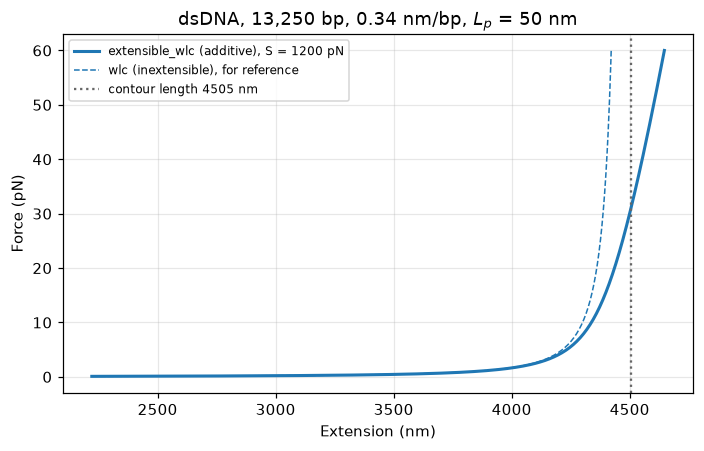

In [22]:
def finite_report(name, *arrays):
    bad = sum(int(np.sum(~np.isfinite(np.asarray(a, dtype=float)))) for a in arrays)
    print(f"{name}: {sum(np.size(a) for a in arrays)} values, non-finite = {bad}")


F_ds = np.geomspace(0.1, 60, 200)
x_ds_ewlc = dna.single_polymer_extension(F_ds, FULL_BP, 50.0, 1200.0, model="extensible_wlc", rise_per_unit_nm=RISE_DS)
x_ds_wlc = dna.single_polymer_extension(F_ds, FULL_BP, 50.0, 1200.0, model="wlc", rise_per_unit_nm=RISE_DS)
Lc_ds = FULL_BP * RISE_DS
finite_report("Figure 8 curves", x_ds_ewlc, x_ds_wlc)
for f in (1, 5, 20, 60):
    i = int(np.argmin(np.abs(F_ds - f)))
    print(f"  F = {F_ds[i]:5.2f} pN: eWLC x = {x_ds_ewlc[i]:7.1f} nm ({x_ds_ewlc[i] / Lc_ds:.3f} Lc), WLC x = {x_ds_wlc[i]:7.1f} nm")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(x_ds_ewlc, F_ds, color="tab:blue", lw=2, label="extensible_wlc (additive), S = 1200 pN")
ax.plot(x_ds_wlc, F_ds, color="tab:blue", ls="--", lw=1, label="wlc (inextensible), for reference")
ax.axvline(Lc_ds, color="0.4", ls=":", label=f"contour length {Lc_ds:.0f} nm")
ax.set_xlabel("Extension (nm)")
ax.set_ylabel("Force (pN)")
ax.set_title("dsDNA, 13,250 bp, 0.34 nm/bp, $L_p$ = 50 nm")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig08_dsDNA_single_polymer_eWLC")
plt.show()

**Figure 8.** Single-polymer force-extension curve for an illustrative 13,250 bp dsDNA molecule from `single_polymer_extension` with `rise_per_unit_nm=0.34`, $L_p$ = 50 nm, and $S$ = 1200 pN, over 0.1–60 pN. The solid line is the additive extensible WLC (`extensible_wlc`), which passes the 4,505 nm contour length (dotted) at high force because of backbone stretch. The dashed line is the inextensible WLC for comparison. Files: [PNG](figures/fig08_dsDNA_single_polymer_eWLC.png), [SVG](figures/fig08_dsDNA_single_polymer_eWLC.svg).

Figure 9 curves: 600 values, non-finite = 0
  F =  1.01 pN: x(Lp 1.0) =  3.78, x(Lp 1.25) =  4.61, x(Lp 1.5) =  5.40 nm
  F =  5.05 pN: x(Lp 1.0) = 12.48, x(Lp 1.25) = 13.86, x(Lp 1.5) = 14.91 nm
  F = 20.11 pN: x(Lp 1.0) = 19.18, x(Lp 1.25) = 19.86, x(Lp 1.5) = 20.36 nm


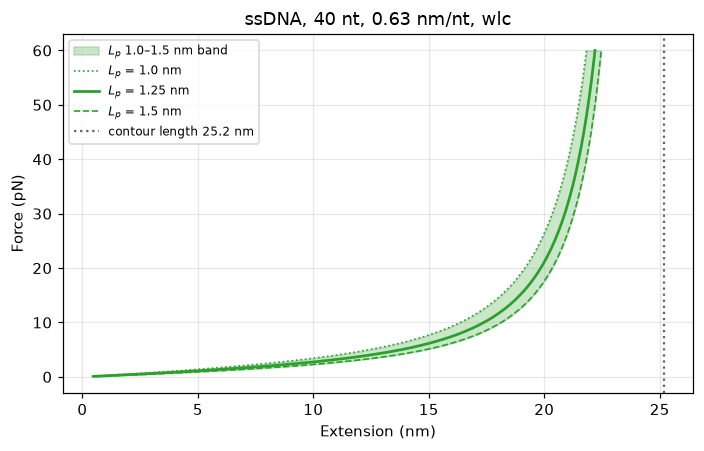

In [23]:
F_ss = np.geomspace(0.1, 60, 200)
ss_curves = {lp: dna.single_polymer_extension(F_ss, TARGET_NT, lp, 800.0, model="wlc", rise_per_unit_nm=RISE_SS) for lp in (1.0, 1.25, 1.5)}
Lc_ss = TARGET_NT * RISE_SS
finite_report("Figure 9 curves", *ss_curves.values())
for f in (1, 5, 20):
    i = int(np.argmin(np.abs(F_ss - f)))
    print(f"  F = {F_ss[i]:5.2f} pN: x(Lp 1.0) = {ss_curves[1.0][i]:5.2f}, x(Lp 1.25) = {ss_curves[1.25][i]:5.2f}, x(Lp 1.5) = {ss_curves[1.5][i]:5.2f} nm")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.fill_betweenx(F_ss, ss_curves[1.0], ss_curves[1.5], color="tab:green", alpha=0.25, label="$L_p$ 1.0–1.5 nm band")
for lp, ls in [(1.0, ":"), (1.25, "-"), (1.5, "--")]:
    ax.plot(ss_curves[lp], F_ss, color="tab:green", ls=ls, lw=1.8 if lp == 1.25 else 1.1, label=f"$L_p$ = {lp} nm")
ax.axvline(Lc_ss, color="0.4", ls=":", label=f"contour length {Lc_ss:.1f} nm")
ax.set_xlabel("Extension (nm)")
ax.set_ylabel("Force (pN)")
ax.set_title("ssDNA, 40 nt, 0.63 nm/nt, wlc")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "fig09_ssDNA_single_polymer_Lp_band")
plt.show()

**Figure 9.** Single-polymer force-extension curves for an illustrative 40 nt ssDNA segment, the length scale of the caliper's short arms, from `single_polymer_extension` with `rise_per_unit_nm=0.63`, $S$ = 800 pN, and `model="wlc"`. The three curves use the `MODEL_GUIDE.md` recommended persistence lengths of 1.0, 1.25, and 1.5 nm, and the shaded band spans that range. The contour length is 25.2 nm (dotted). Files: [PNG](figures/fig09_ssDNA_single_polymer_Lp_band.png), [SVG](figures/fig09_ssDNA_single_polymer_Lp_band.svg).

Figure 10 curves: 480 values, non-finite = 0
  F =  0.99 pN: x_full =  3842.7 nm, x_0T =  3672.2 nm, Delta_0T =  170.5 nm
  F =  4.95 pN: x_full =  4231.6 nm, x_0T =  4043.8 nm, Delta_0T =  187.8 nm
  F = 20.25 pN: x_full =  4437.2 nm, x_0T =  4240.3 nm, Delta_0T =  196.9 nm
  F = 60.00 pN: x_full =  4646.8 nm, x_0T =  4440.6 nm, Delta_0T =  206.2 nm


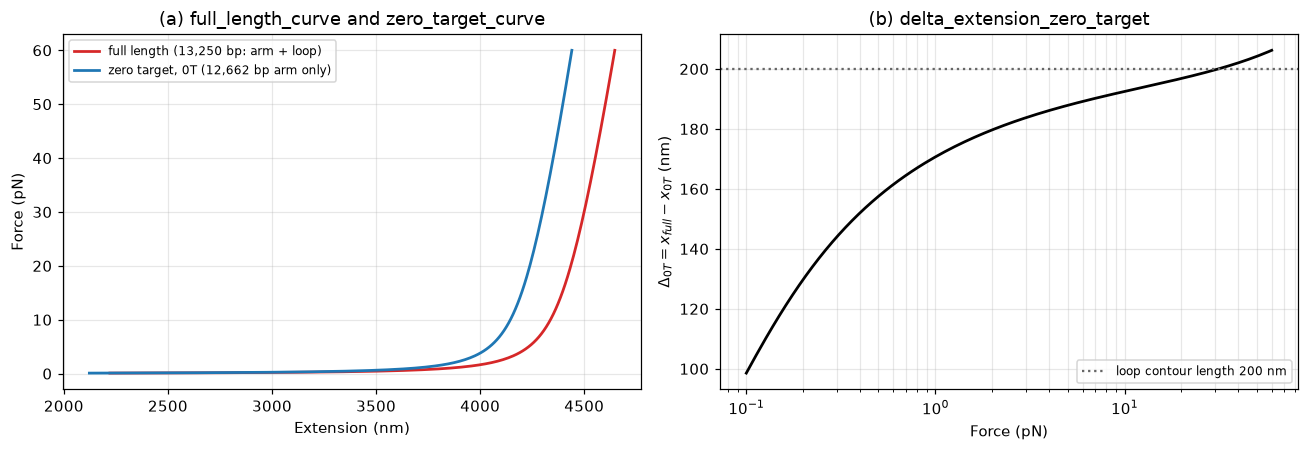

In [24]:
F_c = np.geomspace(0.1, 60, 160)
x_full = dna.full_length_curve(F_c, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS)
x_0T = dna.zero_target_curve(F_c, DS_BP, DS_PARAMS)
delta_0T = dna.delta_extension_zero_target(F_c, DS_BP, LOOP_BP, DS_PARAMS, LOOP_PARAMS)
finite_report("Figure 10 curves", x_full, x_0T, delta_0T)
for f in (1, 5, 20, 60):
    i = int(np.argmin(np.abs(F_c - f)))
    print(f"  F = {F_c[i]:5.2f} pN: x_full = {x_full[i]:7.1f} nm, x_0T = {x_0T[i]:7.1f} nm, Delta_0T = {delta_0T[i]:6.1f} nm")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(x_full, F_c, color="tab:red", lw=1.8, label=f"full length ({FULL_BP:,} bp: arm + loop)")
axes[0].plot(x_0T, F_c, color="tab:blue", lw=1.8, label=f"zero target, 0T ({DS_BP:,} bp arm only)")
axes[0].set_xlabel("Extension (nm)")
axes[0].set_ylabel("Force (pN)")
axes[0].set_title("(a) full_length_curve and zero_target_curve")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(F_c, delta_0T, color="k", lw=1.8)
axes[1].axhline(LOOP_BP * RISE_DS, color="0.4", ls=":", label=f"loop contour length {LOOP_BP * RISE_DS:.0f} nm")
axes[1].set_xscale("log")
axes[1].set_xlabel("Force (pN)")
axes[1].set_ylabel(r"$\Delta_{0T} = x_{full} - x_{0T}$ (nm)")
axes[1].set_title(r"(b) delta_extension_zero_target")
axes[1].legend(fontsize=8, loc="lower right")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
fig.tight_layout()
save_figure(fig, "fig10_looped_construct_full_vs_0T")
plt.show()

**Figure 10.** Looped-construct curves for the illustrative 13,250 bp construct (12,662 bp dsDNA arm plus 588 bp dsDNA loop; both `extensible_wlc`, $L_p$ 50 nm, $S$ 1200 pN, 0.34 nm/bp). (a) The full-length curve, with the loop open in series with the arm (red), and the zero-target (0T) curve, with the loop fully closed so only the arm stretches (blue). (b) The zero-target delta $\Delta_{0T}$ against force on a log axis; it rises steeply at low force and levels off above a few piconewtons, approaching and then slightly exceeding the 200 nm loop contour length (dotted) as the stretch term grows. Files: [PNG](figures/fig10_looped_construct_full_vs_0T.png), [SVG](figures/fig10_looped_construct_full_vs_0T.svg).

Figure 11 curves: 480 values, non-finite = 0
Force points flagged by check_force_split (equal-split fallback or arm mismatch): 0 of 160
Force balance, max |F_target + F_loop - F| = 0.00e+00 pN
  F =  0.99 pN: x_target =  3676.7 nm, parallel block =  4.51 nm, F_target =   0.988 pN, F_loop = 2.82e-03 pN
  F =  4.95 pN: x_target =  4057.5 nm, parallel block = 13.73 nm, F_target =   4.944 pN, F_loop = 8.80e-03 pN
  F = 20.25 pN: x_target =  4260.2 nm, parallel block = 19.88 nm, F_target =  20.235 pN, F_loop = 1.30e-02 pN
  F = 60.00 pN: x_target =  4462.8 nm, parallel block = 22.20 nm, F_target =  59.985 pN, F_loop = 1.46e-02 pN


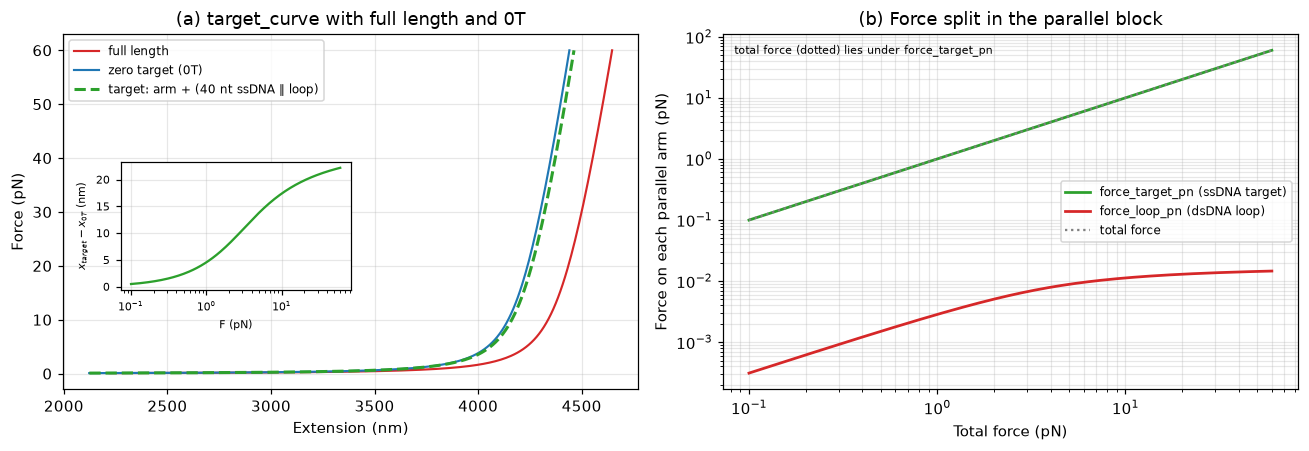

In [25]:
tc = dna.target_curve(F_c, DS_BP, TARGET_NT, LOOP_BP, DS_PARAMS, SS_PARAMS, LOOP_PARAMS)
x_target = tc["extension_nm"]
flags = check_force_split(tc, TARGET_NT, LOOP_BP, SS_PARAMS, LOOP_PARAMS)
finite_report("Figure 11 curves", x_target, tc["force_target_pn"], tc["force_loop_pn"])
print(f"Force points flagged by check_force_split (equal-split fallback or arm mismatch): {int(flags.sum())} of {len(flags)}")
print(f"Force balance, max |F_target + F_loop - F| = {np.max(np.abs(tc['force_target_pn'] + tc['force_loop_pn'] - F_c)):.2e} pN")
for f in (1, 5, 20, 60):
    i = int(np.argmin(np.abs(F_c - f)))
    print(f"  F = {F_c[i]:5.2f} pN: x_target = {x_target[i]:7.1f} nm, parallel block = {tc['parallel_extension_nm'][i]:5.2f} nm, "
          f"F_target = {tc['force_target_pn'][i]:7.3f} pN, F_loop = {tc['force_loop_pn'][i]:.2e} pN")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(x_full, F_c, color="tab:red", lw=1.4, label="full length")
axes[0].plot(x_0T, F_c, color="tab:blue", lw=1.4, label="zero target (0T)")
axes[0].plot(x_target, F_c, color="tab:green", lw=2.0, ls="--", label="target: arm + (40 nt ssDNA ∥ loop)")
axes[0].set_xlabel("Extension (nm)")
axes[0].set_ylabel("Force (pN)")
axes[0].set_title("(a) target_curve with full length and 0T")
axes[0].legend(fontsize=8, loc="upper left")
inset = axes[0].inset_axes([0.10, 0.28, 0.40, 0.36])
inset.plot(F_c, x_target - x_0T, color="tab:green")
inset.set_xscale("log")
inset.set_xlabel("F (pN)", fontsize=7)
inset.set_ylabel(r"$x_{target} - x_{0T}$ (nm)", fontsize=7)
inset.tick_params(labelsize=7)
inset.grid(alpha=0.3)
axes[1].loglog(F_c, tc["force_target_pn"], color="tab:green", lw=1.8, label="force_target_pn (ssDNA target)")
axes[1].loglog(F_c, tc["force_loop_pn"], color="tab:red", lw=1.8, label="force_loop_pn (dsDNA loop)")
axes[1].loglog(F_c, F_c, color="0.5", ls=":", label="total force")
if flags.any():
    axes[1].plot(F_c[flags], tc["force_target_pn"][flags], "kx", label="flagged split")
axes[1].set_xlabel("Total force (pN)")
axes[1].set_ylabel("Force on each parallel arm (pN)")
axes[1].set_title("(b) Force split in the parallel block")
axes[1].legend(fontsize=8, loc="center right")
axes[1].text(0.02, 0.97, "total force (dotted) lies under force_target_pn", transform=axes[1].transAxes, fontsize=7, va="top")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
fig.tight_layout()
save_figure(fig, "fig11_target_curve_force_split")
plt.show()

**Figure 11.** Target-state construct from `target_curve` for the illustrative 13,250 bp construct with a 40 nt ssDNA target block in parallel with the 588 bp loop. The target dictionary sets every key explicitly (`rise_per_unit_nm` 0.63, $L_p$ 1.25 nm, $S$ 800 pN, `wlc`). (a) Total target-state extension (green, dashed) beside the full-length (red) and zero-target (blue) curves; the target curve sits just to the right of 0T, and the inset shows the difference $x_{\mathrm{target}} - x_{0T}$, which is the parallel block's extension and tends toward the 25.2 nm ssDNA contour length. (b) The force split returned by `target_curve`: the short, stiff-in-length ssDNA target carries almost all of the load, and the long dsDNA loop carries only the small force needed to stretch it to the target's length. The dotted total-force line is hidden under the target curve because the two are nearly equal. `check_force_split` flagged none of the 160 force points; flagged points would be marked with crosses. Files: [PNG](figures/fig11_target_curve_force_split.png), [SVG](figures/fig11_target_curve_force_split.svg).

## Where to go next

* `docs/dna_fe_toolkit/MODEL_GUIDE.md` explains the models, parameters, and the finite-size persistence length.
* `tests/` holds the test suite (run `python -m pytest tests` after installing `pytest`, which is not in `requirements.txt`); the tests are also good usage examples.
* `optical_trap_analysis.py` has the rupture tools (`detect_dynamic_rupture_events`, `detect_static_hold_rupture_events`, `add_same_force_extension`, `average_pull_in_trace`) that build on the tidy tables from Part 2.

In [26]:
print("Figures written to", FIG_DIR)
for p in sorted(FIG_DIR.iterdir()):
    print(f"  {p.name:<45} {p.stat().st_size / 1024:8.1f} kB")
shutil.rmtree(TMP, ignore_errors=True)
print("Temporary folder removed:", TMP)

Figures written to /workspace/otc_main_8ad4016/examples/figures
  fig01_psd_calibration.png                        283.0 kB
  fig01_psd_calibration.svg                        161.4 kB
  fig02_tether_detection_fe.png                    162.4 kB
  fig02_tether_detection_fe.svg                    110.6 kB
  fig03_oscillator_edge_correction.png             305.2 kB
  fig03_oscillator_edge_correction.svg             216.6 kB
  fig04_puppet_force_reference.png                 450.3 kB
  fig04_puppet_force_reference.svg                 370.3 kB
  fig05_state_report_tether1_part2.png              21.6 kB
  fig06_measured_delta_vs_model.png                343.9 kB
  fig06_measured_delta_vs_model.svg                174.9 kB
  fig07_model_distance_estimate.png                103.3 kB
  fig07_model_distance_estimate.svg                 29.6 kB
  fig08_dsDNA_single_polymer_eWLC.png              127.2 kB
  fig08_dsDNA_single_polymer_eWLC.svg               20.8 kB
  fig09_ssDNA_single_polymer_Lp_band